<a href="https://colab.research.google.com/github/Abhishekprasad963/Parkinson_Disease/blob/main/Abhishek_parkinson.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install torch torchvision scikit-learn opencv-python matplotlib


In [ ]:
import os
import copy
import numpy as np
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.optim as optim

from torchvision import datasets, transforms, models
from torch.utils.data import DataLoader, random_split

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    roc_auc_score
)

In [ ]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(device)

cuda


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
DATASET_PATH = "/content/drive/MyDrive/Disease_Prediction-20231213T083430Z-001/Disease_Prediction"

In [ ]:
print("Dataset folder exists:", os.path.exists(DATASET_PATH))
print("Main folder contents:", os.listdir(DATASET_PATH))

Dataset folder exists: True
Main folder contents: ['plots', 'PD_new', 'HC_new', 'heatmaps', 'checkpoints']


In [ ]:
hc_path = os.path.join(DATASET_PATH, "HC_new")
pd_path = os.path.join(DATASET_PATH, "PD_new")

print("HC folder exists:", os.path.exists(hc_path))
print("PD folder exists:", os.path.exists(pd_path))

print("Number of HC images:", len(os.listdir(hc_path)))
print("Number of PD images:", len(os.listdir(pd_path)))

HC folder exists: True
PD folder exists: True
Number of HC images: 26
Number of PD images: 290


Preprocess the images

In [ ]:
from torchvision import transforms

train_transform = transforms.Compose([
    transforms.Resize((224,224)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(10),
    transforms.ColorJitter(
        brightness=0.2,
        contrast=0.2
    ),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485,0.456,0.406],
        std=[0.229,0.224,0.225]
    )
])

test_transform = transforms.Compose([
    transforms.Resize((224,224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485,0.456,0.406],
        std=[0.229,0.224,0.225]
    )
])

In [ ]:
from torchvision import datasets

dataset = datasets.ImageFolder(
    root=DATASET_PATH,
    transform=train_transform
)

print("Classes:", dataset.classes)
print("Class to Index:", dataset.class_to_idx)
print("Total Images:", len(dataset))

Classes: ['HC_new', 'PD_new', 'heatmaps', 'plots']
Class to Index: {'HC_new': 0, 'PD_new': 1, 'heatmaps': 2, 'plots': 3}
Total Images: 246


In [ ]:
from torchvision import datasets

# Define the classes we want to keep
allowed_classes = {'HC_new', 'PD_new'}

# Initialize ImageFolder as usual
dataset = datasets.ImageFolder(
    root=DATASET_PATH,
    transform=train_transform
)

# Filter samples and classes in-place
filtered_samples = []
for path, target_idx in dataset.samples:
    class_name = dataset.classes[target_idx]
    if class_name in allowed_classes:
        filtered_samples.append((path, target_idx))

# Re-assign filtered structures
dataset.samples = filtered_samples
dataset.imgs = filtered_samples
dataset.classes = sorted(list(allowed_classes))
dataset.class_to_idx = {cls: idx for idx, cls in enumerate(dataset.classes)}

# Remap targets to match new class indices
dataset.targets = [dataset.class_to_idx[os.path.basename(os.path.dirname(p))] for p, _ in dataset.samples]
dataset.samples = [(p, dataset.class_to_idx[os.path.basename(os.path.dirname(p))]) for p, _ in dataset.samples]
dataset.imgs = dataset.samples

print("Classes remaining:", dataset.classes)
print("Class to Index mapping:", dataset.class_to_idx)
print("Total Images after filtering:", len(dataset))

Classes remaining: ['HC_new', 'PD_new']
Class to Index mapping: {'HC_new': 0, 'PD_new': 1}
Total Images after filtering: 241


Train/test split

In [ ]:
from torch.utils.data import random_split

train_size = int(0.8 * len(dataset))
test_size = len(dataset) - train_size

train_dataset, test_dataset = random_split(
    dataset,
    [train_size, test_size]
)

print("Training Images:", len(train_dataset))
print("Testing Images:", len(test_dataset))


Training Images: 192
Testing Images: 49


Dataloader
16 images at a time

In [ ]:
from torch.utils.data import DataLoader

train_loader = DataLoader(
    train_dataset,
    batch_size=16,
    shuffle=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=16,
    shuffle=False
)

print("DataLoaders Created Successfully!")

DataLoaders Created Successfully!


In [ ]:
# Load pretrained DenseNet121
model = models.densenet121(weights=models.DenseNet121_Weights.DEFAULT)

# Get number of input features
num_features = model.classifier.in_features

# Replace classifier
model.classifier = nn.Sequential(
    nn.Dropout(0.4),
    nn.Linear(num_features, 256),
    nn.ReLU(),
    nn.Dropout(0.3),
    nn.Linear(256, 1)
)

# Move model to GPU/CPU
model = model.to(device)

print(model)

DenseNet(
  (features): Sequential(
    (conv0): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
    (norm0): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (relu0): ReLU(inplace=True)
    (pool0): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
    (denseblock1): _DenseBlock(
      (denselayer1): _DenseLayer(
        (norm1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
        (relu1): ReLU(inplace=True)
        (conv1): Conv2d(64, 128, kernel_size=(1, 1), stride=(1, 1), bias=False)
        (norm2): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
        (relu2): ReLU(inplace=True)
        (conv2): Conv2d(128, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      )
      (denselayer2): _DenseLayer(
        (norm1): BatchNorm2d(96, eps=1e-05, momentum=0.1, affine=True, bias=T

In [ ]:
# Loss Function
criterion = nn.BCEWithLogitsLoss()

# Optimizer
optimizer = optim.Adam(model.parameters(), lr=0.0001)

print("Loss Function and Optimizer Created Successfully!")

Loss Function and Optimizer Created Successfully!


In [ ]:
# Number of epochs
num_epochs = 20

for epoch in range(num_epochs):

    model.train()
    running_loss = 0.0

    for images, labels in train_loader:

        # Move data to GPU/CPU
        images = images.to(device)
        labels = labels.float().unsqueeze(1).to(device)

        # Clear previous gradients
        optimizer.zero_grad()

        # Forward pass
        outputs = model(images)

        # Calculate loss
        loss = criterion(outputs, labels)

        # Backpropagation
        loss.backward()

        # Update weights
        optimizer.step()

        running_loss += loss.item()

    epoch_loss = running_loss / len(train_loader)

    print(f"Epoch [{epoch+1}/{num_epochs}], Loss: {epoch_loss:.4f}")

Epoch [1/20], Loss: 0.4945
Epoch [2/20], Loss: 0.2288
Epoch [3/20], Loss: 0.1505
Epoch [4/20], Loss: 0.1071
Epoch [5/20], Loss: 0.0749
Epoch [6/20], Loss: 0.0590
Epoch [7/20], Loss: 0.0443
Epoch [8/20], Loss: 0.0339
Epoch [9/20], Loss: 0.0343
Epoch [10/20], Loss: 0.0270
Epoch [11/20], Loss: 0.0280
Epoch [12/20], Loss: 0.0239
Epoch [13/20], Loss: 0.0347
Epoch [14/20], Loss: 0.0196
Epoch [15/20], Loss: 0.0253
Epoch [16/20], Loss: 0.0195
Epoch [17/20], Loss: 0.0292
Epoch [18/20], Loss: 0.0218
Epoch [19/20], Loss: 0.0188
Epoch [20/20], Loss: 0.0195


In [ ]:
# Evaluation Mode
model.eval()

all_labels = []
all_predictions = []

with torch.no_grad():

    for images, labels in test_loader:

        images = images.to(device)
        labels = labels.to(device)

        outputs = model(images)

        # Convert logits to probabilities
        predictions = torch.sigmoid(outputs)

        # Convert probabilities to 0 or 1
        predictions = (predictions > 0.5).float()

        all_labels.extend(labels.cpu().numpy())
        all_predictions.extend(predictions.cpu().numpy().flatten())

Calculate Metrices

In [ ]:


accuracy = accuracy_score(all_labels, all_predictions)
precision = precision_score(all_labels, all_predictions)
recall = recall_score(all_labels, all_predictions)
f1 = f1_score(all_labels, all_predictions)

print("Accuracy :", accuracy)
print("Precision:", precision)
print("Recall   :", recall)
print("F1 Score :", f1)

Accuracy : 1.0
Precision: 1.0
Recall   : 1.0
F1 Score : 1.0


Confusion Matrix

[[ 6  0]
 [ 0 43]]


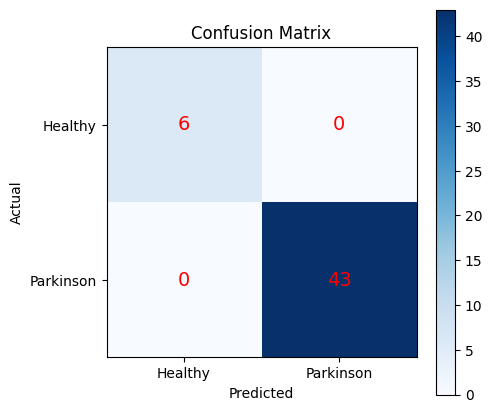

In [ ]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt

cm = confusion_matrix(all_labels, all_predictions)

print(cm)

plt.figure(figsize=(5,5))
plt.imshow(cm, cmap='Blues')
plt.title("Confusion Matrix")
plt.colorbar()

plt.xticks([0,1], ["Healthy","Parkinson"])
plt.yticks([0,1], ["Healthy","Parkinson"])

plt.xlabel("Predicted")
plt.ylabel("Actual")

for i in range(2):
    for j in range(2):
        plt.text(j, i, cm[i,j],
                 ha="center",
                 va="center",
                 color="red",
                 fontsize=14)

plt.show()

classification report

In [ ]:
from sklearn.metrics import classification_report

print(classification_report(
    all_labels,
    all_predictions,
    target_names=["Healthy","Parkinson"]
))

              precision    recall  f1-score   support

     Healthy       1.00      1.00      1.00         6
   Parkinson       1.00      1.00      1.00        43

    accuracy                           1.00        49
   macro avg       1.00      1.00      1.00        49
weighted avg       1.00      1.00      1.00        49



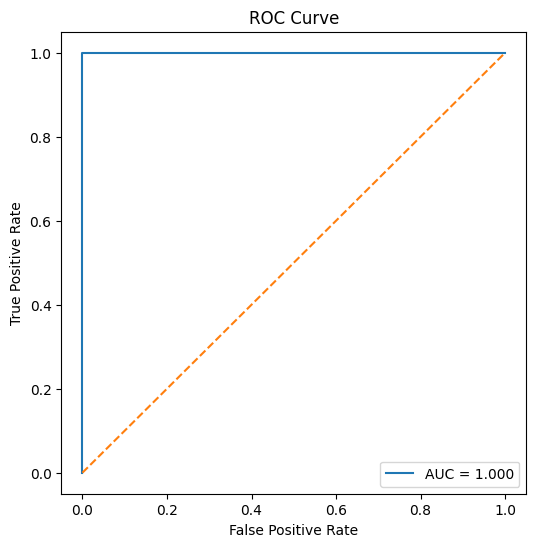

AUC Score: 1.0


In [ ]:
from sklearn.metrics import roc_curve, roc_auc_score
import matplotlib.pyplot as plt

model.eval()

y_true = []
y_score = []

with torch.no_grad():

    for images, labels in test_loader:

        images = images.to(device)

        outputs = model(images)

        probs = torch.sigmoid(outputs)

        y_true.extend(labels.numpy())
        y_score.extend(probs.cpu().numpy().flatten())

auc = roc_auc_score(y_true, y_score)

fpr, tpr, _ = roc_curve(y_true, y_score)

plt.figure(figsize=(6,6))
plt.plot(fpr, tpr, label=f"AUC = {auc:.3f}")
plt.plot([0,1],[0,1],'--')
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend()
plt.show()

print("AUC Score:", auc)

save the trained model

In [ ]:
torch.save(model.state_dict(), "Parkinson_DenseNet121.pth")

print("Model Saved Successfully!")

Model Saved Successfully!


Predict on One Image

In [ ]:
import os, random
from PIL import Image
import torch

folder = "/content/drive/MyDrive/Disease_Prediction-20231213T083430Z-001/Disease_Prediction/HC_new"

image_files = [f for f in os.listdir(folder) if f.lower().endswith((".jpg", ".jpeg", ".png"))]

image_name = random.choice(image_files)
image_path = os.path.join(folder, image_name)

print("Random image selected:", image_name)

image = Image.open(image_path).convert("RGB")
image = test_transform(image).unsqueeze(0).to(device)

model.eval()
with torch.no_grad():
    output = model(image)
    probability = torch.sigmoid(output).item()

if probability > 0.5:
    print("Prediction : Parkinson")
else:
    print("Prediction : Healthy")

print("Confidence :", probability)

Random image selected: PPMI_160890_MR_rsfMRI_RL__br_raw_20220929171453607_75_S1161815_I1624166.jpg
Prediction : Healthy
Confidence : 0.005712365731596947


In [ ]:
!pip install grad-cam

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for grad-cam: filename=grad_cam-1.5.7-py3-none-any.whl size=53345 sha256=5891f5250c9d1cf9f1b99837fb343ffa5d08c3e83f2cf954c85277db67a13d94
  Stored in directory: /root/.cache/pip/wheels/91/36/f0/c2367865493d51b13369769181beca14603d17d6539a5922e3
Successfully built grad-cam
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [grad-cam]


In [ ]:


from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.image import show_cam_on_image

In [ ]:
model.load_state_dict(torch.load("Parkinson_DenseNet121.pth", map_location=device))
model.eval()

print("Model loaded successfully")

Model loaded successfully


In [ ]:
folder = "/content/drive/MyDrive/Disease_Prediction-20231213T083430Z-001/Disease_Prediction/HC_new"

In [ ]:
image_files = [f for f in os.listdir(folder) if f.lower().endswith((".jpg", ".jpeg", ".png"))]

print("Total images found:", len(image_files))

image_name = random.choice(image_files)
image_path = os.path.join(folder, image_name)

print("Selected image:", image_name)
print("Image path:", image_path)

Total images found: 26
Selected image: PPMI_103542_MR_rsfMRI_LR__br_raw_20220106125530278_6_S1093544_I1530517.jpg
Image path: /content/drive/MyDrive/Disease_Prediction-20231213T083430Z-001/Disease_Prediction/HC_new/PPMI_103542_MR_rsfMRI_LR__br_raw_20220106125530278_6_S1093544_I1530517.jpg


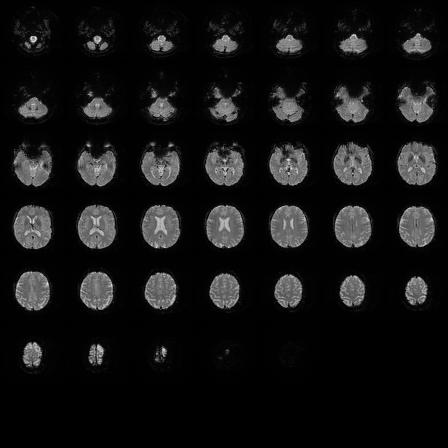

Input shape: torch.Size([1, 3, 224, 224])


In [ ]:
pil_image = Image.open(image_path).convert("RGB")

# original image for display
display(pil_image)

# transformed tensor for model
input_tensor = test_transform(pil_image).unsqueeze(0).to(device)

print("Input shape:", input_tensor.shape)

In [ ]:
with torch.no_grad():
    output = model(input_tensor)
    probability = torch.sigmoid(output).item()

if probability > 0.5:
    prediction = "Parkinson"
else:
    prediction = "Healthy"

print("Prediction:", prediction)
print("Confidence:", probability)

Prediction: Healthy
Confidence: 0.006158497184514999


In [ ]:
target_layers = [model.features[-1]]

In [ ]:
cam = GradCAM(model=model, target_layers=target_layers)

In [ ]:
# Pass targets=None to automatically target the highest scoring category
grayscale_cam = cam(input_tensor=input_tensor, targets=None)
grayscale_cam = grayscale_cam[0]

print("Heatmap shape:", grayscale_cam.shape)

Heatmap shape: (224, 224)


In [ ]:
rgb_image = np.array(pil_image.resize((224, 224))).astype(np.float32) / 255.0
print(rgb_image.shape)

(224, 224, 3)


In [ ]:
visualization = show_cam_on_image(
    rgb_image,
    grayscale_cam,
    use_rgb=True
)

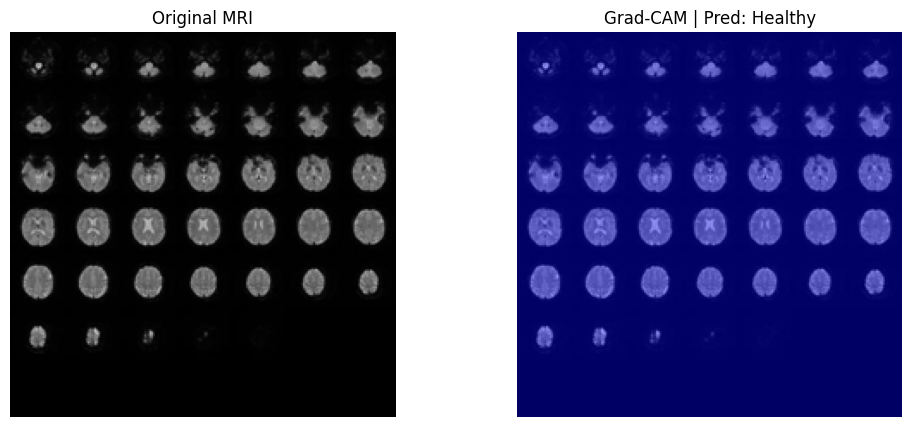

In [ ]:
plt.figure(figsize=(12,5))

plt.subplot(1,2,1)
plt.imshow(rgb_image)
plt.title("Original MRI")
plt.axis("off")

plt.subplot(1,2,2)
plt.imshow(visualization)
plt.title(f"Grad-CAM | Pred: {prediction}")
plt.axis("off")

plt.show()

In [ ]:
print("Image name :", image_name)
print("Prediction :", prediction)
print("Confidence :", round(probability, 4))

Image name : PPMI_103542_MR_rsfMRI_LR__br_raw_20220106125530278_6_S1093544_I1530517.jpg
Prediction : Healthy
Confidence : 0.0062
